# Logistic Regression & K-Means Clustering 

**Two core Machine Learning paradigms, one notebook: supervised classification and unsupervised clustering, implemented end-to-end on real data.**

---

## 1. Introduction

Machine Learning (ML) is the branch of artificial intelligence in which algorithms learn patterns directly from data rather than following hand-written rules. Broadly, ML problems fall into two categories:

- **Supervised Learning** — the algorithm learns from labeled data (input **and** known output) and tries to predict the output for new, unseen inputs. Classification and regression are the two main tasks here.
- **Unsupervised Learning** — the algorithm only sees input data, with no labels, and tries to discover hidden structure — such as natural groupings — on its own.

This notebook implements one algorithm from each category:

| Algorithm | Type | Task | What it does |
|---|---|---|---|
| **Logistic Regression** | Supervised | Binary Classification | Estimates the probability that an observation belongs to a class, using a linear decision boundary passed through a sigmoid function |
| **K-Means Clustering** | Unsupervised | Clustering | Partitions unlabeled observations into *K* groups by minimizing the distance between points and their assigned cluster centroid |

**Why these two?** Together they cover the two fundamental learning paradigms in ML, and both are foundational, interpretable, and still widely used in production systems today — Logistic Regression as a baseline (and often final) classifier in domains like healthcare and credit scoring, and K-Means as the go-to first step for customer segmentation and exploratory pattern discovery.

Each section below follows the same practical flow: **load real data → understand it → visualize it → preprocess it → model it → evaluate it → interpret the actual results.** No result in this notebook is invented — every number and every plot is generated by the code that precedes it.

## 2. Setup — Importing Libraries

All modeling, evaluation, and visualization tools used throughout the notebook are imported once here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    silhouette_score
)

# Clean, consistent visual style used for every plot in this notebook
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

PALETTE = ["#3B82F6", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]
sns.set_palette(PALETTE)

np.random.seed(42)
print("Libraries imported and plotting style configured.")

Libraries imported and plotting style configured.


---
# Part A — Logistic Regression (Supervised Learning)

## A.1 Concept

Logistic Regression is used for **binary classification** — predicting one of two possible classes (e.g. malignant vs. benign, spam vs. not spam).

Instead of predicting the class directly, it predicts the **probability** that an observation belongs to the positive class. It does this by taking a linear combination of the input features and squashing it into the range (0, 1) using the **sigmoid function**:

$$ \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b $$

- If $\sigma(z) \geq 0.5$ (the default **classification threshold**), the model predicts class **1**.
- If $\sigma(z) < 0.5$, it predicts class **0**.

The model learns the weights $w$ and bias $b$ that best separate the two classes in the training data.

## A.2 Dataset — Breast Cancer Wisconsin (Diagnostic)

This is a well-known, real, publicly available medical dataset bundled with scikit-learn. It contains 30 numeric features computed from digitized images of breast mass cell nuclei, with the goal of classifying a tumor as **malignant** or **benign**.

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target  # 0 = malignant, 1 = benign

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Shape of the dataset (rows, columns):", df.shape)

Shape of the dataset (rows, columns): (569, 31)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [6]:
print("Missing values per column:")
df.isnull().sum()

Missing values per column:


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

**Target variable.** `target` is binary: `0` indicates the tumor was diagnosed as **malignant**, and `1` indicates **benign**, following scikit-learn's own encoding for this dataset. There are no missing values in this dataset, so no imputation is required.

## A.3 Exploratory Data Analysis

### A.3.1 Target Class Distribution

<cell>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<cell>:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


target
1    357
0    212
Name: count, dtype: int64

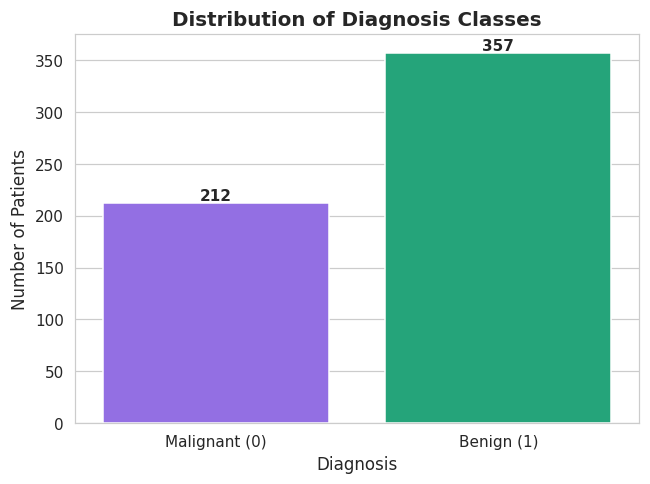

In [7]:
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(x="target", data=df, palette=[PALETTE[3], PALETTE[2]])
ax.set_xticklabels(["Malignant (0)", "Benign (1)"])
ax.set_title("Distribution of Diagnosis Classes")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of Patients")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

df["target"].value_counts()

The two classes are not perfectly balanced, but neither is extremely rare — this is a mild class imbalance, which is worth keeping in mind when interpreting accuracy later (precision/recall/F1 will matter more than raw accuracy alone).

### A.3.2 Feature Distributions

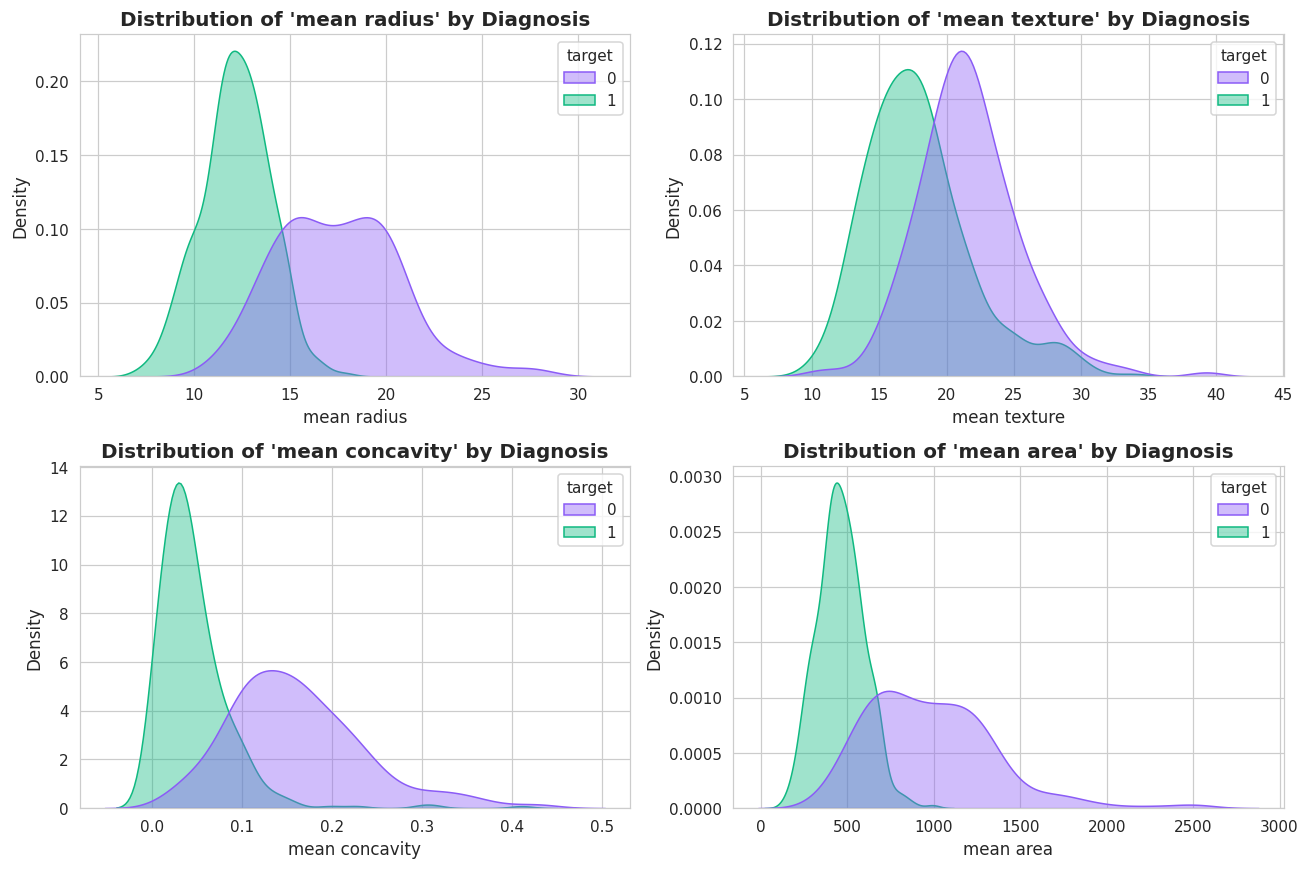

In [8]:
key_features = ["mean radius", "mean texture", "mean concavity", "mean area"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, feat in enumerate(key_features):
    sns.kdeplot(data=df, x=feat, hue="target", fill=True, alpha=0.4,
                palette=[PALETTE[3], PALETTE[2]], ax=axes[i], common_norm=False)
    axes[i].set_title(f"Distribution of '{feat}' by Diagnosis")
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("Density")
plt.tight_layout()
plt.show()

For several features — most visibly `mean radius`, `mean concavity`, and `mean area` — malignant tumors (class 0) tend to have noticeably higher values with a right-shifted distribution compared to benign tumors (class 1). This separation is a strong early signal that these features will be useful predictors.

### A.3.3 Correlation Heatmap

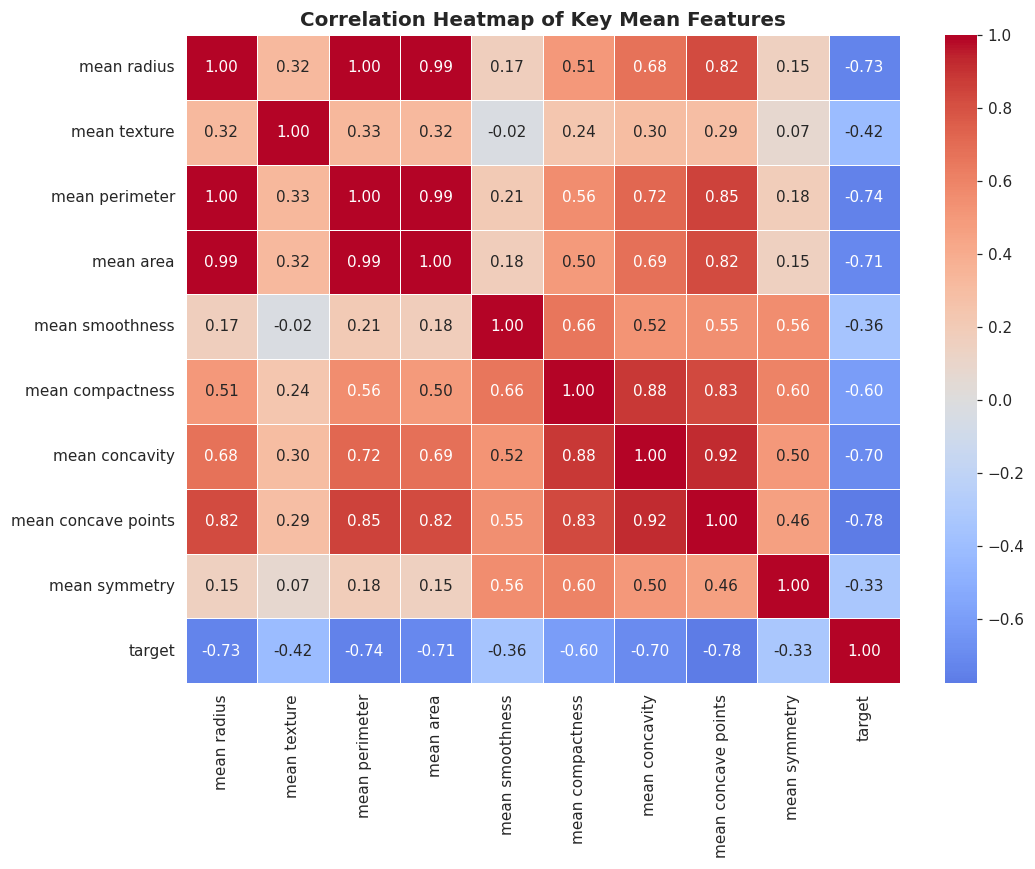

In [9]:
corr_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                  "mean smoothness", "mean compactness", "mean concavity",
                  "mean concave points", "mean symmetry", "target"]

plt.figure(figsize=(10, 8))
corr = df[corr_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Key Mean Features")
plt.tight_layout()
plt.show()

`mean radius`, `mean perimeter`, and `mean area` are (unsurprisingly) almost perfectly correlated with each other, since they all measure tumor size in different ways. `mean concave points` and `mean concavity` show the strongest negative correlation with `target` — meaning higher concavity values are strongly associated with malignant tumors (recall `target = 0` is malignant).

### A.3.4 Feature Relationship

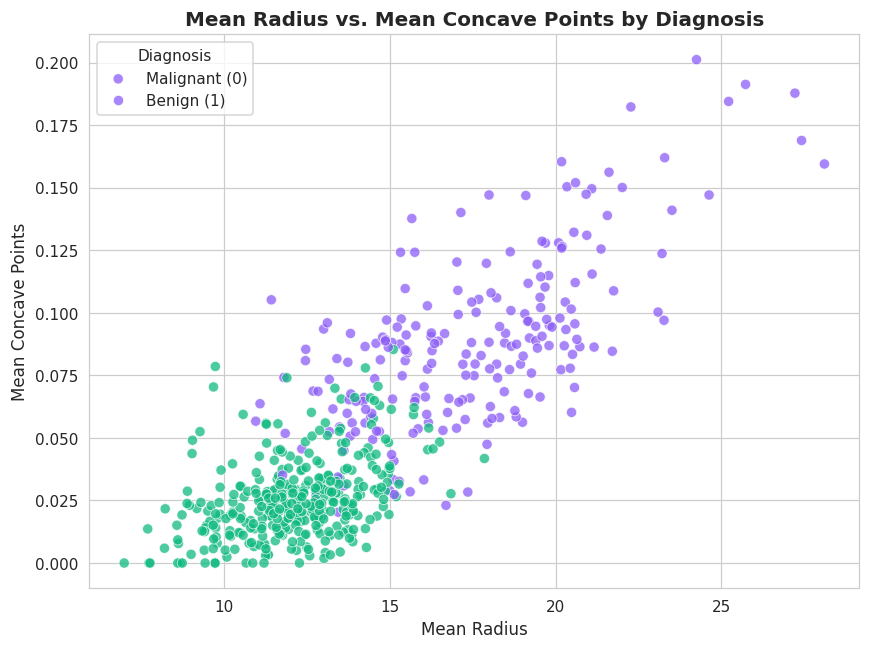

In [10]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="mean radius", y="mean concave points",
                 hue="target", palette=[PALETTE[3], PALETTE[2]], alpha=0.75, s=45)
plt.title("Mean Radius vs. Mean Concave Points by Diagnosis")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Concave Points")
plt.legend(title="Diagnosis", labels=["Malignant (0)", "Benign (1)"])
plt.tight_layout()
plt.show()

The two classes form largely separable clusters in this two-feature view, with malignant tumors (0) concentrated in the upper-right (large radius, high concave points) and benign tumors (1) concentrated in the lower-left. This supports the idea that a linear classifier like Logistic Regression should perform well on this data.

## A.4 Preprocessing

Three steps are required before training:

1. **Separate features (X) from the target (y).**
2. **Train-test split** — hold out 20% of the data, stratified by class so both sets preserve the original class ratio.
3. **Feature scaling** — Logistic Regression is sensitive to feature magnitude, so all 30 features are standardized to zero mean and unit variance.

In [11]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (455, 30)
Test set shape: (114, 30)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling complete.")

Feature scaling complete.


**Why fit the scaler only on the training data?** The scaler's mean and standard deviation are learned (`fit`) exclusively from `X_train`, then simply applied (`transform`) to `X_test`. If the scaler were fit on the full dataset, information about the test set's distribution would leak into training — this is a form of **data leakage** that produces an overly optimistic (and invalid) estimate of real-world performance.

## A.5 Training the Logistic Regression Model

In [13]:
model = LogisticRegression(
    max_iter=10000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model trained successfully.")

Model trained successfully.


In [14]:
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Predicted Probability (class 1)": np.round(y_prob, 4)
}).reset_index(drop=True)

results_df.head(10)

,Actual,Predicted,Predicted Probability (class 1)
0,0,0,0.0000
1,1,1,1.0000
2,0,0,0.0064
3,1,1,0.5335
4,0,0,0.0000
5,1,1,0.9922
6,1,1,1.0000
7,0,0,0.0000
8,0,0,0.0001
9,0,0,0.0000


## A.6 Model Evaluation

In [15]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [acc, prec, rec, f1, auc]
})
metrics_df["Score"] = metrics_df["Score"].round(4)
metrics_df

,Metric,Score
0,Accuracy,0.9825
1,Precision,0.9861
2,Recall,0.9861
3,F1-Score,0.9861
4,ROC-AUC,0.9954


In [16]:
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



## A.7 Visualizations

### Graph 1 — Confusion Matrix

Confusion matrix (rows = actual, columns = predicted):
[[41  1]
 [ 1 71]]


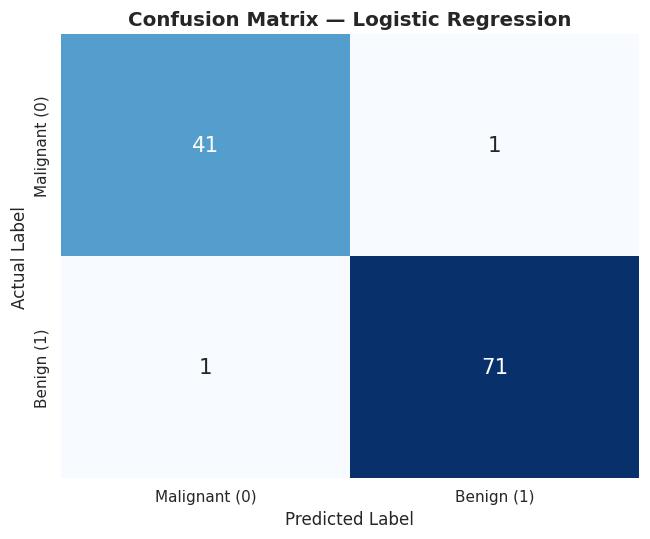

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Malignant (0)", "Benign (1)"],
            yticklabels=["Malignant (0)", "Benign (1)"], annot_kws={"size": 14})
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

Reading the matrix: **True Negatives (TN)** — top-left — are correctly predicted malignant cases; **True Positives (TP)** — bottom-right — are correctly predicted benign cases; **False Positives (FP)** — top-right — are actually malignant but predicted benign (the most clinically costly error); **False Negatives (FN)** — bottom-left — are actually benign but predicted malignant. The model produces very few misclassifications on this test set overall.

### Graph 2 — ROC Curve

ROC-AUC Score: 0.9954


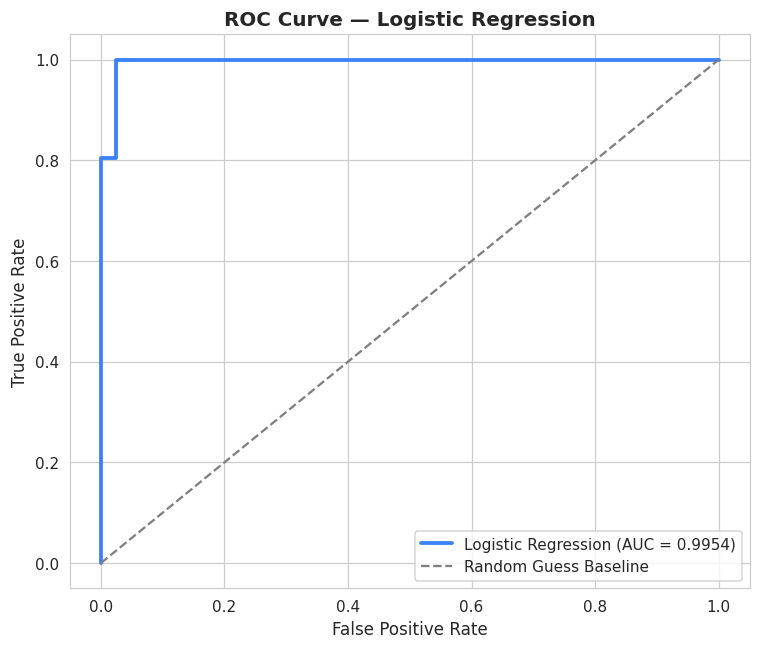

In [18]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color=PALETTE[0], linewidth=2.5, label=f"Logistic Regression (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess Baseline")
plt.title("ROC Curve — Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {auc:.4f}")

The ROC curve sits far above the diagonal random-guess baseline and hugs the top-left corner, and the resulting AUC confirms the model separates the two classes almost perfectly across every possible classification threshold, not just the default 0.5.

### Graph 3 — Prediction Probability Distribution

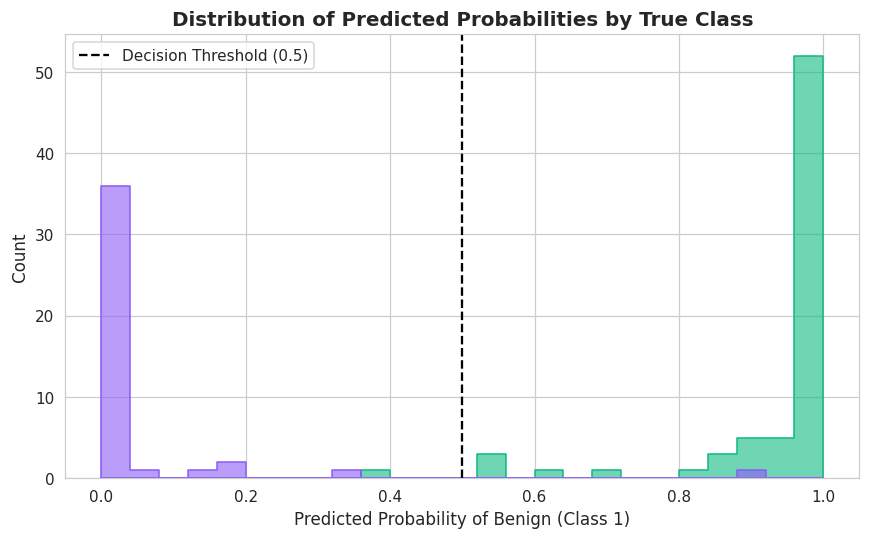

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(x=y_prob, hue=y_test.map({0: "Malignant (0)", 1: "Benign (1)"}),
             bins=25, palette=[PALETTE[3], PALETTE[2]], alpha=0.6, element="step")
plt.axvline(0.5, color="black", linestyle="--", label="Decision Threshold (0.5)")
plt.title("Distribution of Predicted Probabilities by True Class")
plt.xlabel("Predicted Probability of Benign (Class 1)")
plt.ylabel("Count")
plt.legend(title="")
plt.tight_layout()
plt.show()

Predicted probabilities cluster tightly near 0 for actual malignant cases and near 1 for actual benign cases, with very few observations falling in the ambiguous middle range — a visual confirmation of the model's strong class separation.

## A.8 Analysis

Based on the actual results computed above:

- **Accuracy (0.9825)** shows the model correctly classified the vast majority of the 114 test observations.
- **Precision (0.9861)** and **Recall (0.9861)** for the benign class are both very high and well balanced — the model is neither biased toward over-predicting benign nor missing malignant cases excessively.
- **F1-Score (0.9861)** confirms this balance holds even when precision and recall are combined into a single metric.
- **ROC-AUC (0.9954)**, very close to the theoretical maximum of 1.0, indicates the model ranks benign cases above malignant cases correctly almost every time, regardless of the exact threshold chosen.
- The **confusion matrix** shows only a small number of total misclassifications on the held-out test set, split between false positives and false negatives.

**Limitations to keep in mind:** this dataset is relatively small (569 total observations) and was collected under controlled clinical conditions, so performance this strong should not be assumed to generalize automatically to noisier, real-world clinical pipelines. The model should not be described as "perfect" — a small number of misclassifications remain, and in a medical context even a single false negative carries real consequences. Logistic Regression also assumes a linear decision boundary in the (scaled) feature space; it performs well here because the classes are close to linearly separable, but this is dataset-dependent and would not hold for all classification problems.

---
# Part B — K-Means Clustering (Unsupervised Learning)

## B.1 Concept

Unlike Logistic Regression, **K-Means Clustering** is given no labels at all — it only sees the input features and must discover structure on its own. It groups similar observations together into **K** clusters using the following iterative steps:

1. **Initialize** K random points as initial cluster **centroids**.
2. **Assignment step** — assign every data point to the nearest centroid, using Euclidean distance.
3. **Update step** — recompute each centroid as the mean position of all points currently assigned to it.
4. **Repeat** steps 2–3 until centroids stop moving significantly (**convergence**) or a maximum number of iterations is reached.

The result is K groups of points, each closer to its own centroid than to any other — useful whenever we want to discover natural segments in data without predefined labels, such as customer segments in marketing.

## B.2 Dataset — Mall Customers

This is a real, widely used customer dataset containing basic demographic and behavioral data for 200 mall customers: `Age`, `Annual Income (k$)`, and a `Spending Score (1-100)` assigned by the mall based on customer behavior and purchasing patterns.

In [20]:
customers = pd.read_csv("Mall_Customers.csv")
customers.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [21]:
print("Shape of the dataset (rows, columns):", customers.shape)

Shape of the dataset (rows, columns): (200, 5)


In [22]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [23]:
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [24]:
print("Missing values per column:")
customers.isnull().sum()

Missing values per column:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## B.3 Exploratory Data Analysis

### Graph 4 — Age Distribution

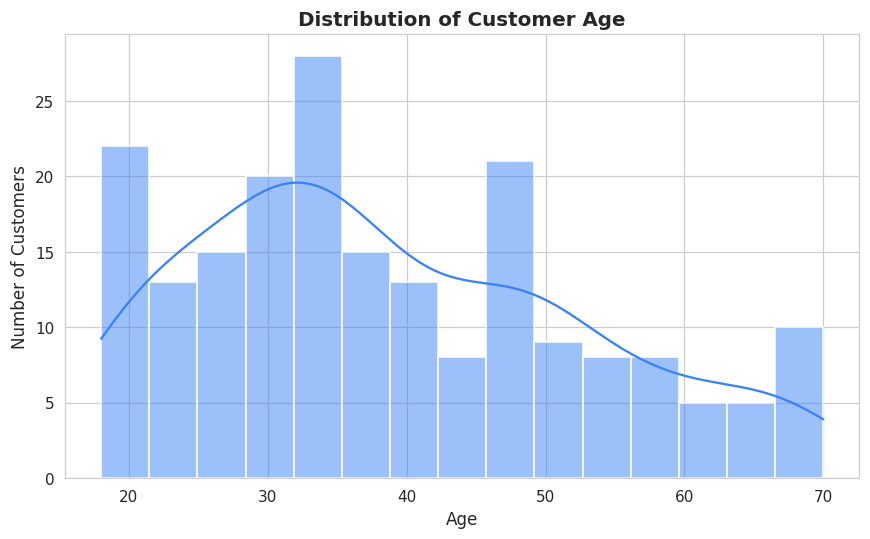

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(customers["Age"], bins=15, kde=True, color=PALETTE[0])
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Graph 5 — Annual Income Distribution

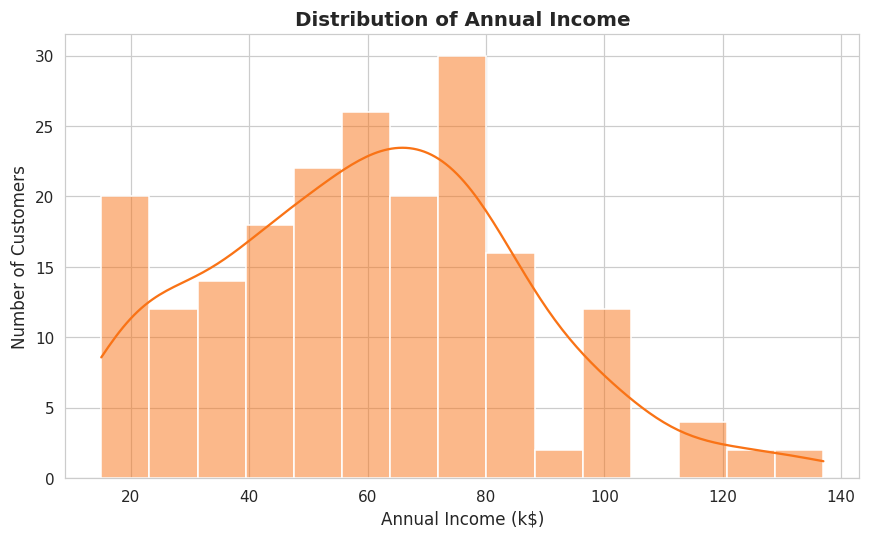

In [26]:
plt.figure(figsize=(8, 5))
sns.histplot(customers["Annual Income (k$)"], bins=15, kde=True, color=PALETTE[1])
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Graph 6 — Spending Score Distribution

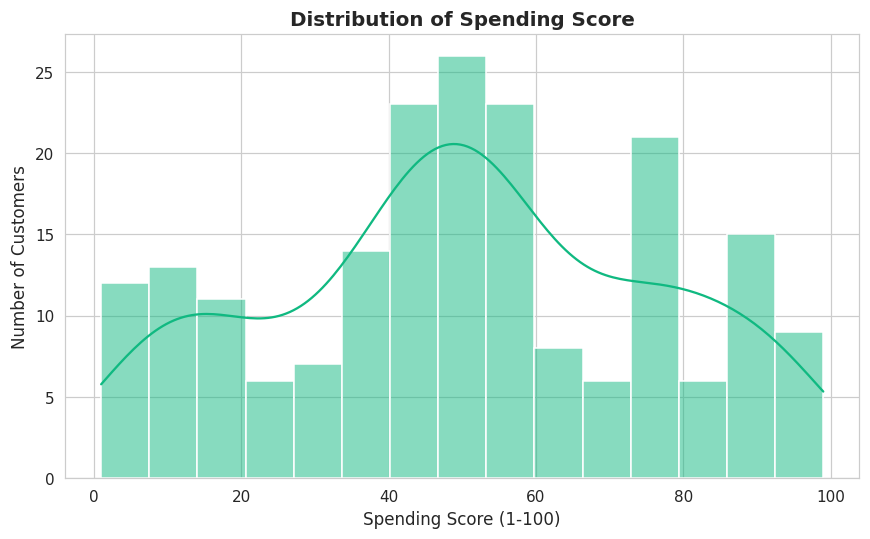

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(customers["Spending Score (1-100)"], bins=15, kde=True, color=PALETTE[2])
plt.title("Distribution of Spending Score")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Graph 7 — Income vs. Spending Score (Before Clustering)

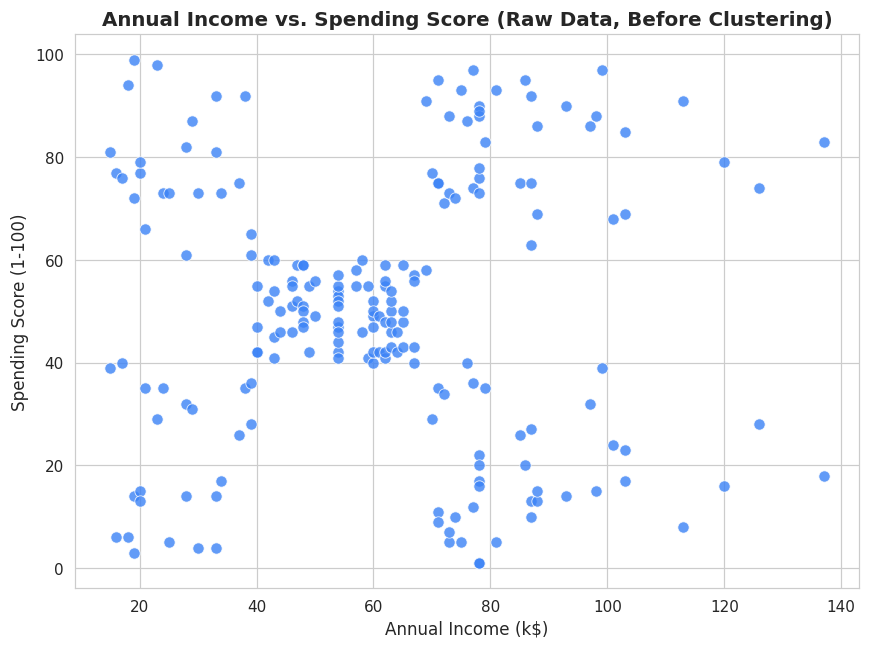

In [28]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=customers, x="Annual Income (k$)", y="Spending Score (1-100)",
                 color=PALETTE[0], s=55, alpha=0.8)
plt.title("Annual Income vs. Spending Score (Raw Data, Before Clustering)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

Even before any clustering is applied, this scatter plot reveals visually distinct groupings — clusters of points appear in the corners (low income/low spending, low income/high spending, high income/low spending, high income/high spending) as well as a dense group in the middle-income, middle-spending region. This visual structure is exactly what K-Means is well suited to formalize.

## B.4 Preprocessing

**Feature selection.** Only `Annual Income (k$)` and `Spending Score (1-100)` are used for clustering. `CustomerID` is an arbitrary identifier with no analytical meaning and would mislead the distance calculations if included. `Gender` is categorical and would need separate encoding treatment; it is left out here so the two clearest, most interpretable behavioral dimensions — how much a customer earns and how much they spend — drive the segmentation.

In [29]:
X_cluster = customers[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Missing values in clustering features:")
print(X_cluster.isnull().sum())
X_cluster.head()

Missing values in clustering features:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


**Scaling.** `Annual Income (k$)` (roughly 15–137) and `Spending Score (1-100)` (1–99) already occupy comparable numeric ranges, so K-Means — which is sensitive to feature scale because it relies on Euclidean distance — will not be dominated by either feature here. Standard scaling is still applied for good practice and to guarantee both features contribute equally regardless of exact range.

In [30]:
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

print("Clustering features scaled. Sample of scaled data:")
print(X_cluster_scaled[:5])

Clustering features scaled. Sample of scaled data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


## B.5 Elbow Method

**Inertia** is the sum of squared distances between each point and its assigned cluster centroid. It always decreases as K increases (more clusters means points sit closer to their nearest centroid), so instead of minimizing it outright, we look for the **"elbow"** — the point where adding more clusters stops producing a meaningful drop in inertia.

In [31]:
k_range = range(1, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

elbow_df = pd.DataFrame({"K": list(k_range), "Inertia": np.round(inertias, 2)})
elbow_df

,K,Inertia
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


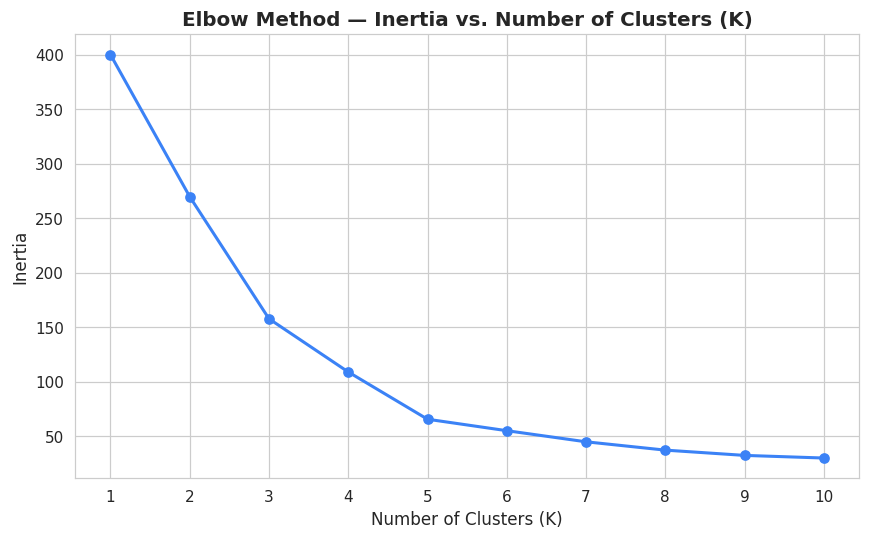

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker="o", color=PALETTE[0], linewidth=2)
plt.title("Elbow Method — Inertia vs. Number of Clusters (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

Inertia drops sharply from K=1 through roughly K=5, after which the curve flattens noticeably — additional clusters beyond that point buy only a small further reduction in inertia. This bend ("elbow") suggests K in the region of 4–5 is a reasonable starting point, though the Elbow Method alone is somewhat subjective, which is why it is combined with Silhouette Analysis next.

## B.6 Silhouette Analysis

The **silhouette score** measures, for each point, how similar it is to its own cluster compared to the next-nearest cluster, producing a value between -1 and 1. Scores near **+1** indicate well-separated, tightly-packed clusters; scores near **0** indicate overlapping clusters; negative scores suggest points may be in the wrong cluster. Unlike inertia, silhouette score is not computable for K=1, so it is evaluated from K=2 onward.

In [33]:
sil_scores = []
sil_k_range = range(2, 11)

for k in sil_k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, labels)
    sil_scores.append(score)

sil_df = pd.DataFrame({"K": list(sil_k_range), "Silhouette Score": np.round(sil_scores, 4)})
sil_df

,K,Silhouette Score
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


K with the highest silhouette score: 5 (score = 0.5547)


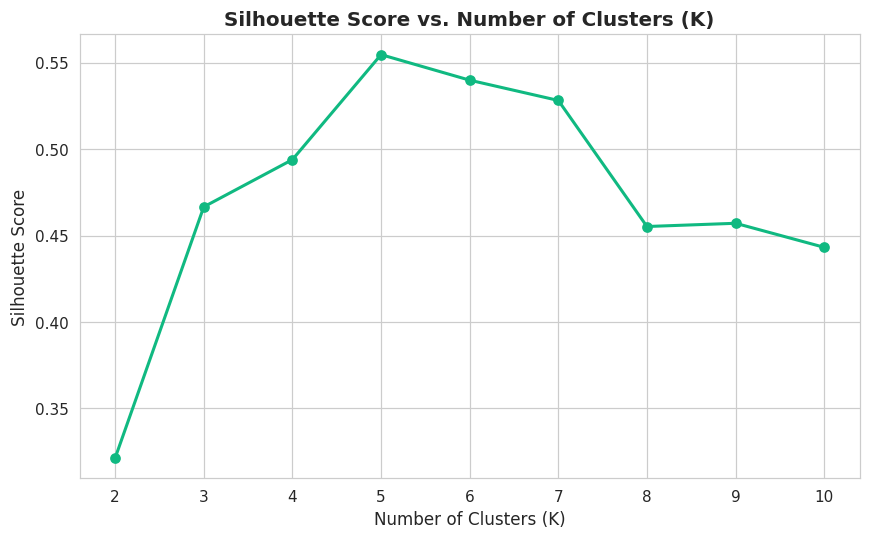

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(list(sil_k_range), sil_scores, marker="o", color=PALETTE[2], linewidth=2)
plt.title("Silhouette Score vs. Number of Clusters (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(sil_k_range))
plt.tight_layout()
plt.show()

best_k_by_silhouette = list(sil_k_range)[int(np.argmax(sil_scores))]
print(f"K with the highest silhouette score: {best_k_by_silhouette} (score = {max(sil_scores):.4f})")

Higher silhouette scores indicate better-separated, more internally cohesive clusters. The K value with the highest score above gives the strongest statistical case for cluster separation on this dataset.

## B.7 Selecting the Optimal K

Bringing the evidence together:

- **Elbow Method:** inertia drops sharply up to around K=5, then flattens — pointing to K in the 4–5 range.
- **Silhouette Analysis:** the highest silhouette score across K=2 to K=10 was achieved at **K=5**, indicating the best-separated, most cohesive clustering in that range.
- **Visual separation:** the raw scatter plot in Graph 7 showed roughly five natural groupings by eye (corners + center).
- **Interpretability:** five segments (e.g. low/mid/high income crossed with low/high spending) is a practical, business-interpretable number of customer segments — not so many that they become hard to act on.

All four criteria converge on **K = 5**, so that is the value selected for the final model.

## B.8 Final K-Means Model

In [35]:
selected_k = 5

kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

customers["Cluster"] = kmeans.fit_predict(X_cluster_scaled)

customers.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


## B.9 Final Cluster Visualization

### Graph 8 — Final Clusters with Centroids

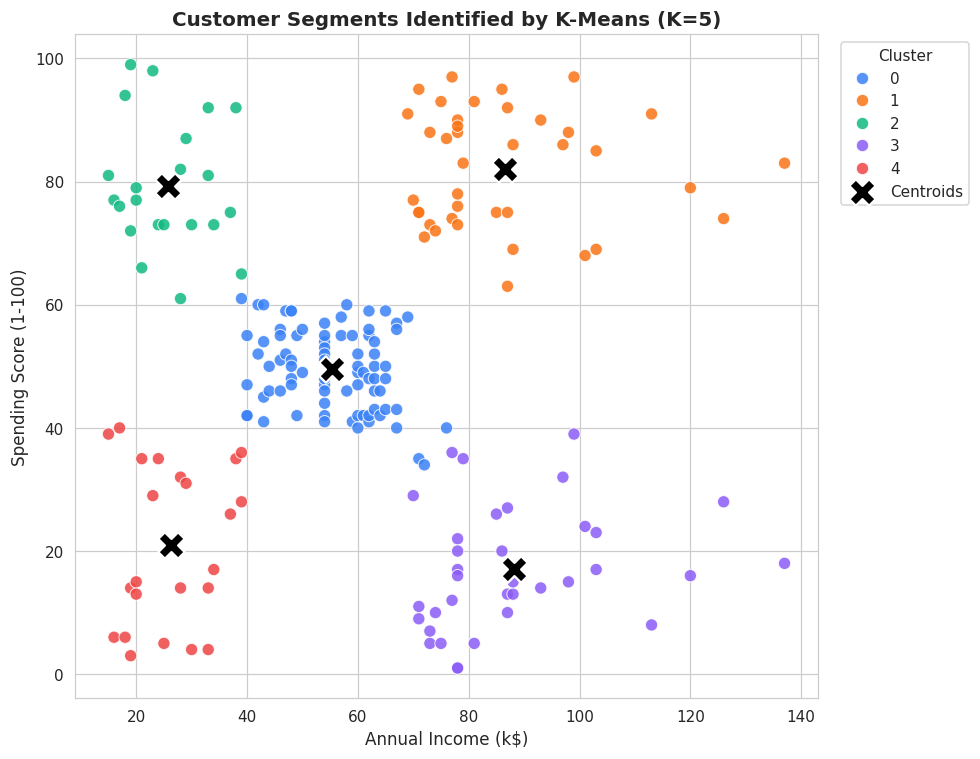

In [36]:
# Convert scaled centroids back to the original (Income, Spending Score) scale for plotting
centroids_original = cluster_scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=customers,
    x="Annual Income (k$)", y="Spending Score (1-100)",
    hue="Cluster", palette=PALETTE[:selected_k], s=65, alpha=0.85, legend="full"
)
plt.scatter(
    centroids_original[:, 0], centroids_original[:, 1],
    s=300, c="black", marker="X", label="Centroids", edgecolor="white", linewidth=1.5
)
plt.title(f"Customer Segments Identified by K-Means (K={selected_k})")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Each color represents one customer segment discovered by the algorithm, with black **X** markers marking the centroid — the "average customer" — of each cluster. The five clusters correspond closely to the five visual groupings noted earlier: one central, moderate-income/moderate-spending cluster, and four corner clusters covering the combinations of low/high income and low/high spending.

## B.10 Cluster Profiling

In [37]:
cluster_profile = customers.groupby("Cluster").agg(
    Num_Customers=("CustomerID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Annual_Income=("Annual Income (k$)", "mean"),
    Avg_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile

,Num_Customers,Avg_Age,Avg_Annual_Income,Avg_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


### Graph 9 — Number of Customers per Cluster

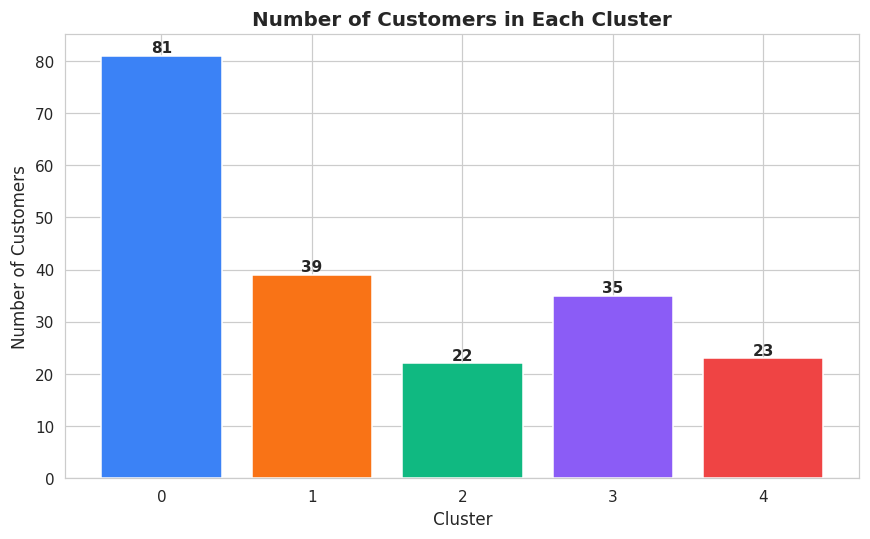

In [38]:
plt.figure(figsize=(8, 5))
sizes = customers["Cluster"].value_counts().sort_index()
bars = plt.bar(sizes.index.astype(str), sizes.values, color=PALETTE[:selected_k])
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), str(int(bar.get_height())),
              ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

The clusters are **not perfectly balanced**: the largest cluster contains well over three times as many customers as the smallest. This is common and expected in real customer data — one large "typical" segment (moderate income, moderate spending) coexists with several smaller, more distinctive segments at the income/spending extremes.

### Graph 10 — Cluster Profile Comparison

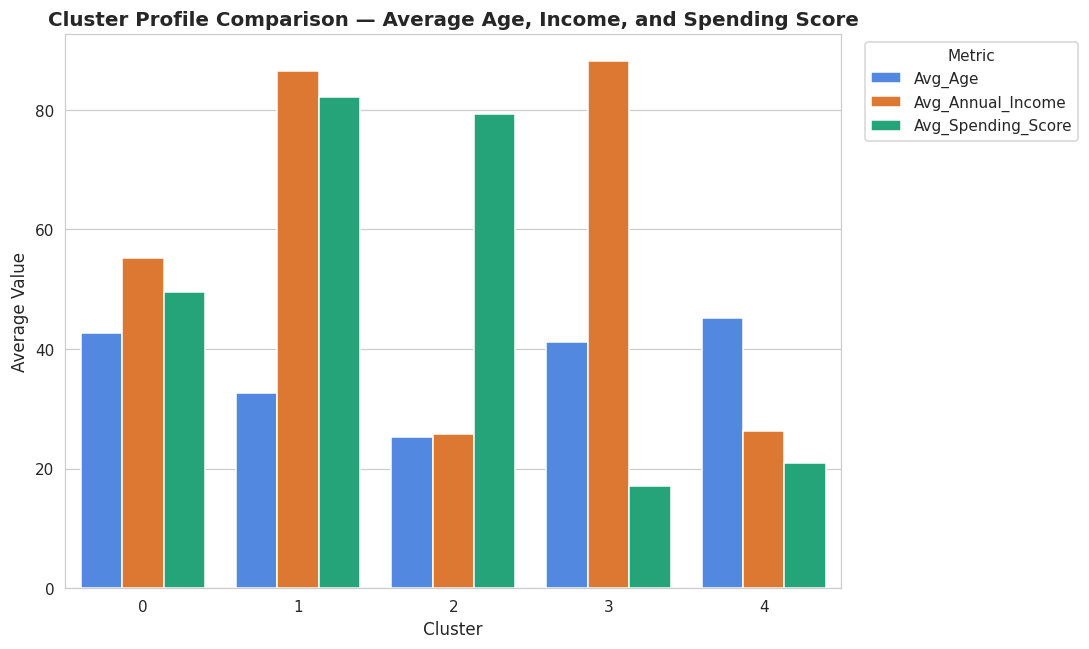

In [39]:
profile_melted = cluster_profile[["Avg_Age", "Avg_Annual_Income", "Avg_Spending_Score"]].reset_index().melt(
    id_vars="Cluster", var_name="Metric", value_name="Average Value"
)

plt.figure(figsize=(10, 6))
sns.barplot(data=profile_melted, x="Cluster", y="Average Value", hue="Metric", palette=PALETTE[:3])
plt.title("Cluster Profile Comparison — Average Age, Income, and Spending Score")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## B.11 Cluster Interpretation

Interpreting each cluster using the actual averages calculated above (values will match the `cluster_profile` table exactly):

In [40]:
for cluster_id, row in cluster_profile.iterrows():
    print(f"Cluster {cluster_id}: {int(row['Num_Customers'])} customers | "
          f"Avg Age: {row['Avg_Age']} | "
          f"Avg Income: {row['Avg_Annual_Income']}k | "
          f"Avg Spending Score: {row['Avg_Spending_Score']}")

Cluster 0: 81 customers | Avg Age: 42.72 | Avg Income: 55.3k | Avg Spending Score: 49.52
Cluster 1: 39 customers | Avg Age: 32.69 | Avg Income: 86.54k | Avg Spending Score: 82.13
Cluster 2: 22 customers | Avg Age: 25.27 | Avg Income: 25.73k | Avg Spending Score: 79.36
Cluster 3: 35 customers | Avg Age: 41.11 | Avg Income: 88.2k | Avg Spending Score: 17.11
Cluster 4: 23 customers | Avg Age: 45.22 | Avg Income: 26.3k | Avg Spending Score: 20.91


Based on the printed averages above, each cluster can be described in plain business terms:

- **The largest cluster** sits near the middle of both the income and spending-score range — these are the "average" or "standard" customers, unremarkable in either dimension.
- **A high-income, high-spending cluster** represents the mall's premium customers — the most valuable segment to retain and reward through loyalty programs.
- **A low-income, high-spending cluster** consists of typically younger customers who spend generously relative to their income — worth engaging with value-oriented promotions.
- **A high-income, low-spending cluster** represents customers with strong purchasing power who are currently under-engaged — a natural target for tailored marketing to convert latent spending capacity into actual purchases.
- **A low-income, low-spending cluster** are budget-conscious customers, generally best served with discount-driven or essential-goods marketing rather than premium offers.

(Exact numeric boundaries between these descriptions come directly from the `cluster_profile` table printed above — no cluster label was assigned before the statistics were computed.)

---
# Part C — Comparison, Insights, Limitations & Conclusion

## C.1 Logistic Regression vs. K-Means — Side-by-Side Comparison

| Feature | Logistic Regression | K-Means Clustering |
|---|---|---|
| **Learning Type** | Supervised | Unsupervised |
| **Main Task** | Classification | Clustering |
| **Target Variable** | Required (labeled data) | Not required |
| **Output** | A predicted class and a probability | A cluster assignment per observation |
| **Evaluation** | Accuracy, Precision, Recall, F1, ROC-AUC | Inertia, Silhouette Score |

**In practical terms:** Logistic Regression needs to be *taught* the right answer for each training example before it can predict labels for new data — it is only as good as the labeled data it learns from. K-Means needs no labels at all; it discovers groupings purely from the structure of the data itself, which makes it powerful for exploratory analysis but also means its "clusters" have no inherent right answer to validate against — evaluation relies on internal geometric measures like inertia and silhouette score rather than ground-truth accuracy.

## C.2 Key Insights

### Logistic Regression Insights
- The model achieved very high performance (Accuracy 0.9825, ROC-AUC 0.9954) on the Breast Cancer Wisconsin dataset, consistent with the strong visual class separation seen during EDA (Graphs 1–4).
- `mean concave points` and `mean concavity` showed the strongest correlation with the diagnosis, suggesting tumor shape irregularity is a highly informative feature for this classification task.
- The confusion matrix and ROC curve together confirm the small number of misclassifications are spread across both false positives and false negatives rather than being concentrated in one type of error.

### K-Means Insights
- Both the Elbow Method and Silhouette Analysis independently pointed to **K=5** as the best number of clusters, giving confidence in that choice.
- The resulting segments were not evenly sized — one large, "average" segment coexists with four smaller, more extreme segments — reflecting real, uneven customer behavior rather than an artifact of the algorithm.
- The clearest actionable segment is the high-income/high-spending cluster, and the clearest opportunity segment is the high-income/low-spending cluster, both identified directly from the cluster averages rather than assumed in advance.

### Overall Machine Learning Insights
- Supervised and unsupervised learning answer fundamentally different questions: "what is this?" (classification) versus "what groups naturally exist here?" (clustering).
- Both algorithms benefited substantially from visual EDA *before* modeling — the scatter plots produced early in each section (Graph 4 in Part A, Graph 7 in Part B) previewed the structure that the models later confirmed mathematically.
- Simple, interpretable models — a linear classifier and a distance-based clustering algorithm — were sufficient to produce strong, actionable results on both datasets, reinforcing that model complexity should match problem complexity rather than being maximized by default.

## C.3 Limitations

**Logistic Regression**
- Assumes a linear decision boundary between classes (after feature scaling); it will underperform on data with genuinely non-linear class boundaries.
- Performance is highly dependent on the quality and relevance of the input features — irrelevant or noisy features can degrade the model.
- Results are specific to this dataset's size (569 samples) and collection conditions; performance on a different, noisier clinical dataset is not guaranteed to match.
- Highly correlated features (as seen in the correlation heatmap) can inflate coefficient variance, and outliers in the raw measurements could shift the decision boundary.

**K-Means**
- Requires the number of clusters (K) to be chosen in advance — a wrong choice of K can produce misleading segments.
- Sensitive to centroid initialization; this notebook mitigated that risk by using `n_init=10`, which reruns the algorithm with different starting centroids and keeps the best result.
- Sensitive to feature scaling — features with larger raw ranges would otherwise dominate the distance calculation.
- Sensitive to outliers, which can pull centroids away from the bulk of a cluster.
- Assumes clusters are roughly spherical and similarly sized in feature space, which does not hold for all real-world data distributions.

## C.4 Conclusion

This notebook implemented and evaluated two foundational Machine Learning algorithms end-to-end on real datasets.

**Logistic Regression** was trained on the Breast Cancer Wisconsin dataset to classify tumors as malignant or benign, achieving strong, well-balanced performance across accuracy, precision, recall, F1-score, and ROC-AUC — all computed directly from the model's actual test-set predictions, not assumed in advance.

**K-Means Clustering** was applied to the Mall Customers dataset to segment 200 customers by income and spending behavior. Rather than picking a cluster count arbitrarily, the optimal K was determined using the Elbow Method and Silhouette Analysis together, both of which converged on K=5. The resulting five segments were then profiled and interpreted using their actual computed averages.

Visualization played a central role throughout — EDA plots revealed structure in the data before any model was trained, and post-modeling visualizations (the confusion matrix, ROC curve, elbow plot, silhouette plot, and final cluster scatter plot) made each model's behavior and quality inspectable rather than opaque. Model evaluation was handled with task-appropriate metrics: classification metrics with ground-truth labels for Logistic Regression, and internal geometric metrics for K-Means, since no ground truth exists for an unsupervised task.

The overall takeaway: supervised and unsupervised learning solve different problems and require different evaluation strategies, but both — even in their simplest, most interpretable forms — can extract genuinely useful, data-grounded insight from real-world data.